In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
df = pd.read_csv("Electric Vehicle Data Analysis.csv")

print("Dataset loaded successfully")

FileNotFoundError: [Errno 2] No such file or directory: 'Electric Vehicle Data Analysis.csv'

In [ ]:
import glob

files = glob.glob("/content/*.csv")
print(files)

[]


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Electric Vehicle Data Analysis.csv to Electric Vehicle Data Analysis.csv


In [ ]:
df = pd.read_csv("Electric Vehicle Data Analysis.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJYGDEE1L,King,Seattle,WA,98122.0,2020,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,291,0,37.0,125701579,POINT (-122.30839 47.610365),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
1,7SAYGDEE9P,Snohomish,Bothell,WA,98021.0,2023,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,1.0,244285107,POINT (-122.179458 47.802589),PUGET SOUND ENERGY INC,5.306105e+10
2,5YJSA1E4XK,King,Seattle,WA,98109.0,2019,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,270,0,36.0,156773144,POINT (-122.34848 47.632405),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
3,5YJSA1E27G,King,Issaquah,WA,98027.0,2016,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,210,0,5.0,165103011,POINT (-122.03646 47.534065),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
4,5YJYGDEE5M,Kitsap,Suquamish,WA,98392.0,2021,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,23.0,205138552,POINT (-122.55717 47.733415),PUGET SOUND ENERGY INC,5.303594e+10


In [ ]:
df.shape

(177866, 17)

In [ ]:
df.columns

Index(['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year',
       'Make', 'Model', 'Electric Vehicle Type',
       'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range',
       'Base MSRP', 'Legislative District', 'DOL Vehicle ID',
       'Vehicle Location', 'Electric Utility', '2020 Census Tract'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177866 entries, 0 to 177865
Data columns (total 17 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         177866 non-null  object 
 1   County                                             177861 non-null  object 
 2   City                                               177861 non-null  object 
 3   State                                              177866 non-null  object 
 4   Postal Code                                        177861 non-null  float64
 5   Model Year                                         177866 non-null  int64  
 6   Make                                               177866 non-null  object 
 7   Model                                              177866 non-null  object 
 8   Electric Vehicle Type                              177866 non-null  object

In [ ]:
df.isnull().sum()

,0
VIN (1-10),0
County,5
City,5
State,0
Postal Code,5
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
VIN (1-10),object
County,object
City,object
State,object
Postal Code,float64
Model Year,int64
Make,object
Model,object
Electric Vehicle Type,object
Clean Alternative Fuel Vehicle (CAFV) Eligibility,object


In [ ]:
df_clean = df.copy()

print("Clean copy created")

Clean copy created


In [ ]:
text_columns = [
    "County",
    "City",
    "Electric Utility",
    "Vehicle Location"
]

for column in text_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

print("Text missing values handled")

Text missing values handled


In [ ]:
location_columns = [
    "Postal Code",
    "Legislative District",
    "2020 Census Tract"
]

for column in location_columns:
    df_clean[column] = df_clean[column].fillna("Unknown").astype(str)

print("Location columns cleaned")

Location columns cleaned


In [ ]:
df_clean.isnull().sum()

,0
VIN (1-10),0
County,0
City,0
State,0
Postal Code,0
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


In [ ]:
top_makes = df_clean["Make"].value_counts().head(10)

top_makes

,count
Make,
TESLA,79659
NISSAN,13998
CHEVROLET,13678
FORD,9199
BMW,7570
KIA,7432
TOYOTA,6288
VOLKSWAGEN,5004
JEEP,4480


## EDA 1: Top 10 Electric Vehicle Manufacturers

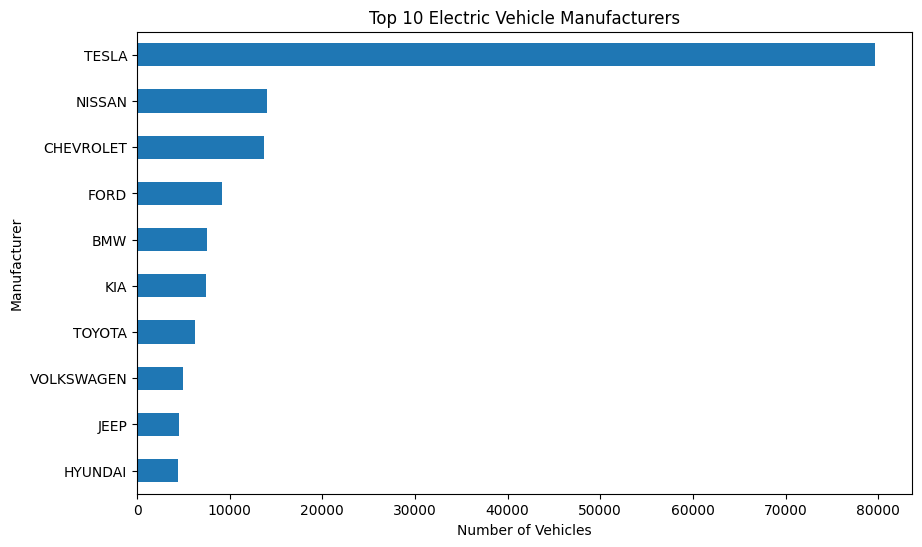

In [ ]:
plt.figure(figsize=(10, 6))

top_makes.sort_values().plot(kind="barh")

plt.title("Top 10 Electric Vehicle Manufacturers")
plt.xlabel("Number of Vehicles")
plt.ylabel("Manufacturer")

plt.show()

In [ ]:
top_models = df_clean["Model"].value_counts().head(10)

top_models

,count
Model,
MODEL Y,35989
MODEL 3,30092
LEAF,13366
MODEL S,7735
BOLT EV,6821
MODEL X,5796
VOLT,4796
ID.4,3937
WRANGLER,3392


## EDA 2: Top 10 Electric Vehicle Models

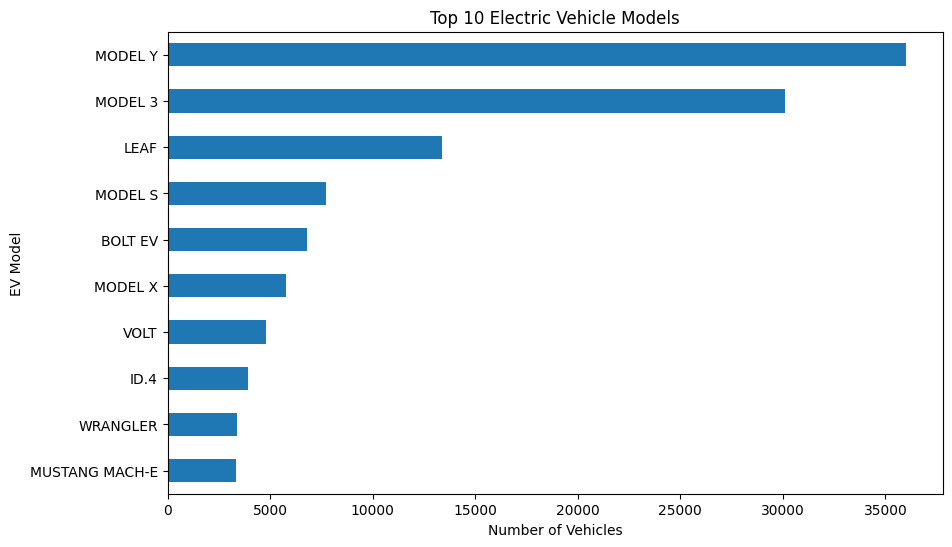

In [ ]:
plt.figure(figsize=(10, 6))

top_models.sort_values().plot(kind="barh")

plt.title("Top 10 Electric Vehicle Models")
plt.xlabel("Number of Vehicles")
plt.ylabel("EV Model")

plt.show()

### Finding

MODEL Y is the most frequently recorded EV model in the dataset with 35,989 records, followed by MODEL 3 with 30,092 records. The LEAF ranks third with 13,366 records. The results show that a small number of EV models account for a substantial portion of the vehicle records.

In [ ]:
ev_type_counts = df_clean["Electric Vehicle Type"].value_counts()

ev_type_counts

,count
Electric Vehicle Type,
Battery Electric Vehicle (BEV),139210
Plug-in Hybrid Electric Vehicle (PHEV),38656


## EDA 3: Electric Vehicle Type Distribution

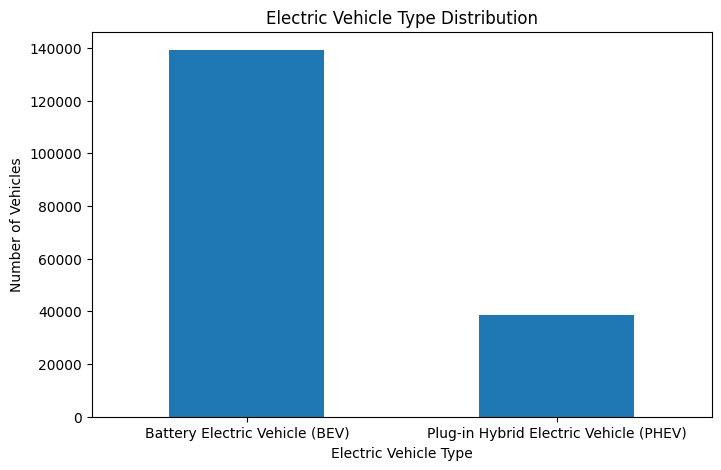

In [ ]:
plt.figure(figsize=(8, 5))

ev_type_counts.plot(kind="bar")

plt.title("Electric Vehicle Type Distribution")
plt.xlabel("Electric Vehicle Type")
plt.ylabel("Number of Vehicles")

plt.xticks(rotation=0)
plt.show()

### Finding

Battery Electric Vehicles (BEVs) are the dominant vehicle type in the dataset, with 139,210 records, while Plug-in Hybrid Electric Vehicles (PHEVs) account for 38,656 records. BEVs represent approximately 78.3% of the dataset, compared with approximately 21.7% for PHEVs. This indicates that battery-electric vehicles are substantially more common than plug-in hybrid vehicles in the analyzed dataset.

## EDA 4: Electric Range Analysis

In [ ]:
# Basic statistics of Electric Range

df_clean["Electric Range"].describe()

,Electric Range
count,177866.000000
mean,58.842162
std,91.981298
min,0.000000
25%,0.000000
50%,0.000000
75%,75.000000
max,337.000000


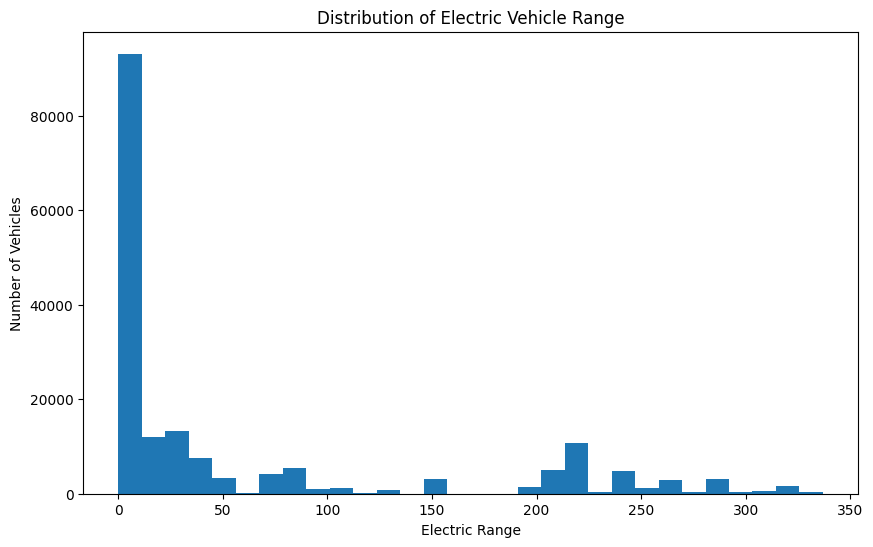

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(df_clean["Electric Range"], bins=30)

plt.title("Distribution of Electric Vehicle Range")
plt.xlabel("Electric Range")
plt.ylabel("Number of Vehicles")

plt.show()

### Finding

The electric range distribution is highly concentrated at 0, with a smaller number of vehicles having positive electric ranges. The average electric range is 58.84, while the maximum recorded range is 337. The median electric range is 0, indicating that at least half of the records have an electric range of 0 in this dataset. The distribution is therefore highly uneven, with a large concentration at zero and a smaller number of vehicles distributed across higher ranges.

## EDA 5: Average Electric Range by Manufacturer

In [ ]:
# Calculate average electric range for each manufacturer

range_by_make = (
    df_clean.groupby("Make")["Electric Range"]
    .mean()
    .sort_values(ascending=False)
)

range_by_make.head(10)

,Electric Range
Make,
JAGUAR,203.741379
WHEEGO ELECTRIC CARS,100.000000
TH!NK,100.000000
CHEVROLET,94.552785
FIAT,85.645408
NISSAN,80.348836
TESLA,77.338204
SMART,62.325926
AZURE DYNAMICS,56.000000


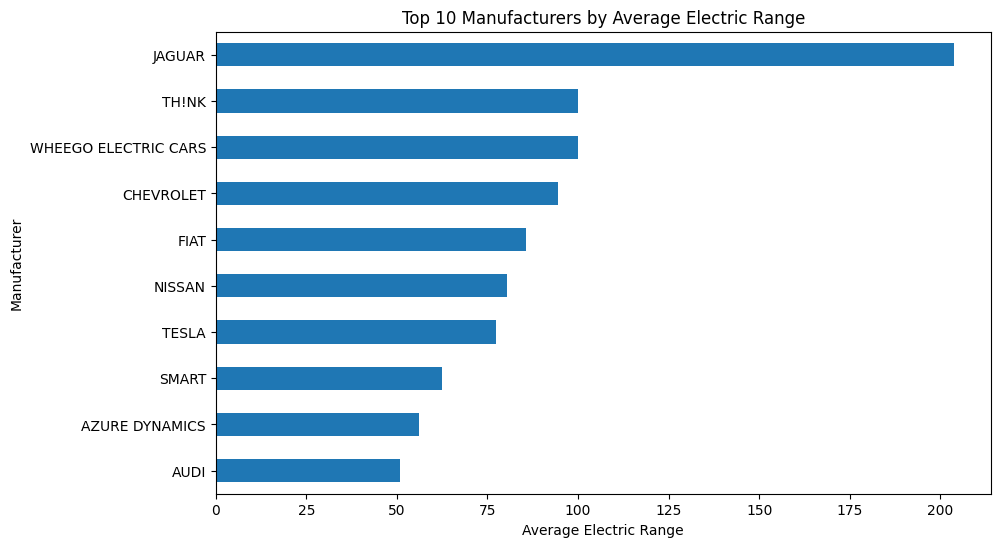

In [ ]:
plt.figure(figsize=(10, 6))

range_by_make.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Manufacturers by Average Electric Range")
plt.xlabel("Average Electric Range")
plt.ylabel("Manufacturer")

plt.show()

Finding: Jaguar has the highest average electric range among the top 10 manufacturers, with an average range of approximately 203.74. TH!NK and Wheego Electric Cars follow with an average range of 100, while Chevrolet has an average range of approximately 94.55. Among the major manufacturers shown, Nissan and Tesla have average ranges of approximately 80.35 and 77.34, respectively. Overall, the analysis shows considerable variation in average electric range across manufacturers.

EDA 6: CAFV Eligibility Analysis

In [ ]:
cafv_counts = df_clean["Clean Alternative Fuel Vehicle (CAFV) Eligibility"].value_counts()

cafv_counts

,count
Clean Alternative Fuel Vehicle (CAFV) Eligibility,
Eligibility unknown as battery range has not been researched,91950
Clean Alternative Fuel Vehicle Eligible,66331
Not eligible due to low battery range,19585


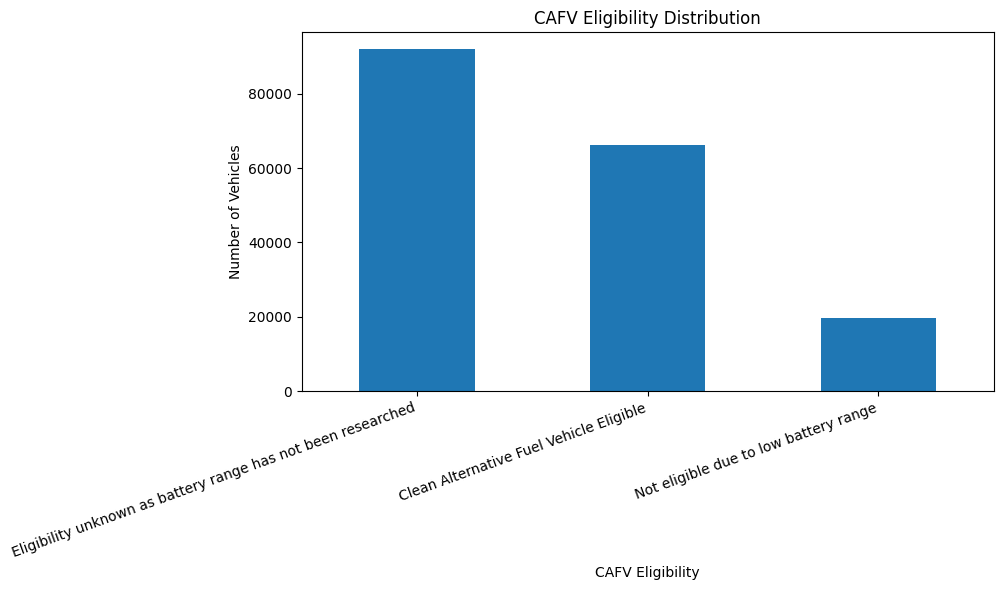

In [ ]:
plt.figure(figsize=(10, 6))

cafv_counts.plot(kind="bar")

plt.title("CAFV Eligibility Distribution")
plt.xlabel("CAFV Eligibility")
plt.ylabel("Number of Vehicles")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.show()

EDA 7: Electric Vehicle Distribution by State

In [ ]:
state_counts = df_clean["State"].value_counts()

state_counts.head(10)

,count
State,
WA,177477
CA,101
VA,46
MD,31
TX,23
NC,16
IL,15
CO,12
AZ,10


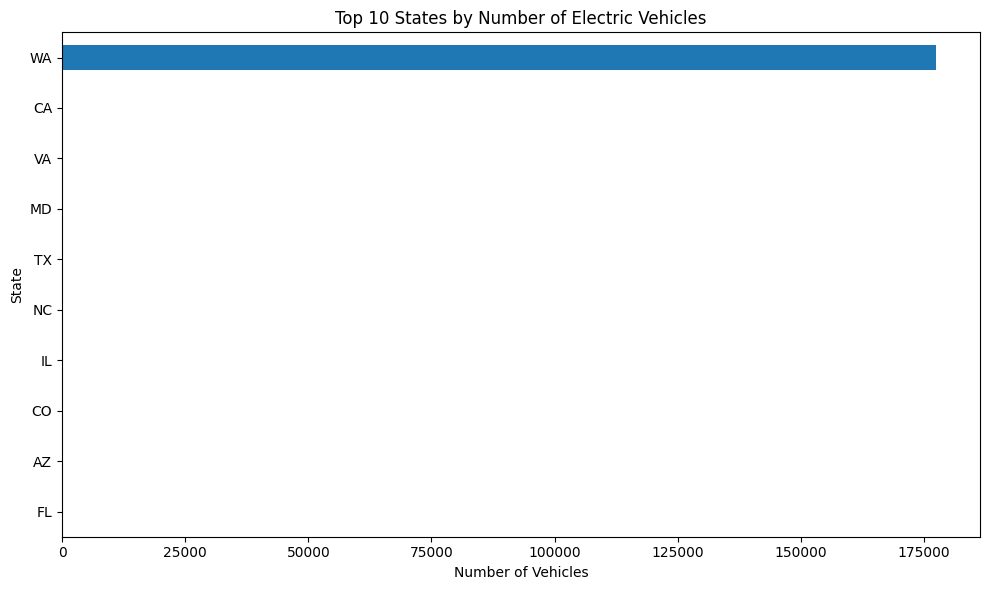

In [ ]:
plt.figure(figsize=(10, 6))

state_counts.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 States by Number of Electric Vehicles")
plt.xlabel("Number of Vehicles")
plt.ylabel("State")

plt.tight_layout()
plt.show()

Finding: Washington (WA) has the highest number of electric vehicle records in the dataset, with 177,477 vehicles. California (CA) follows with 101 records, while Virginia (VA) has 46 records. The remaining states have considerably fewer records. The distribution is highly concentrated in Washington, indicating that the dataset is strongly dominated by EV records from this state.

EDA 8: Electric Vehicle Distribution by City

In [ ]:
city_counts = df_clean["City"].value_counts()

city_counts.head(10)

,count
City,
Seattle,29447
Bellevue,8931
Redmond,6478
Vancouver,6193
Bothell,5863
Kirkland,5362
Sammamish,5280
Renton,4980
Olympia,4299


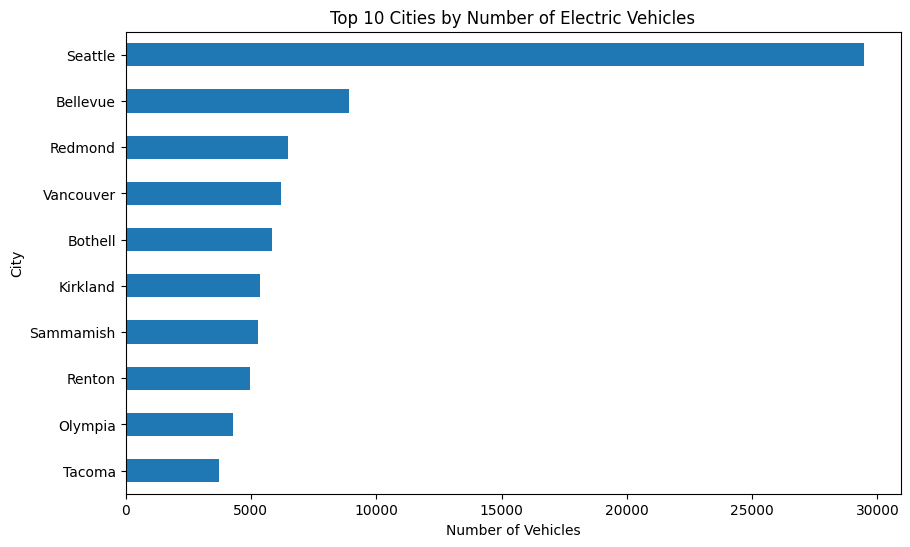

In [ ]:
top_cities = city_counts.head(10)

plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Number of Electric Vehicles")
plt.xlabel("Number of Vehicles")
plt.ylabel("City")

plt.show()

Finding: Seattle has the highest number of electric vehicle records among the top 10 cities, with 29,447 vehicles. Bellevue follows with 8,931 records, while Redmond has 6,478 records. The remaining cities have fewer than 6,200 records each. Overall, the distribution is highly concentrated in Seattle, which has substantially more EV records than the other cities.

## EDA 9: Electric Vehicle Model Year Distribution

In [ ]:
year_counts = df_clean["Model Year"].value_counts().sort_index()

year_counts

,count
Model Year,
1997,1
1998,1
1999,5
2000,7
2002,2
2003,1
2008,20
2010,23
2011,775


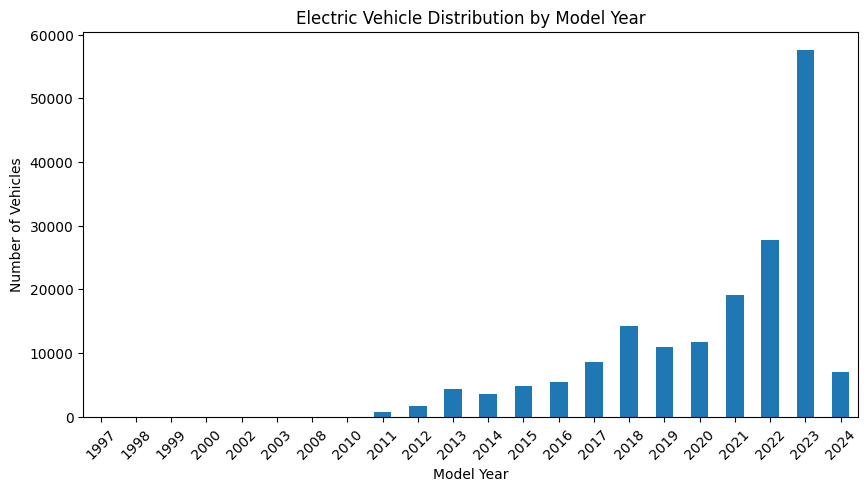

In [ ]:
plt.figure(figsize=(10, 5))

year_counts.plot(kind="bar")

plt.title("Electric Vehicle Distribution by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Number of Vehicles")
plt.xticks(rotation=45)

plt.show()

Finding: The distribution of electric vehicles by model year shows a clear increase in the number of records in recent years. The year 2023 has the highest number of electric vehicle records, followed by 2022 and 2021. Earlier model years have comparatively fewer records. This indicates that the dataset is strongly concentrated toward newer electric vehicle models, particularly those from 2021–2023.

## EDA 10: Electric Vehicle Base MSRP Analysis

In [ ]:
df_clean["Base MSRP"].describe()

,Base MSRP
count,177866.000000
mean,1073.109363
std,8358.624956
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,845000.000000


In [ ]:
msrp_nonzero = df_clean[df_clean["Base MSRP"] > 0]["Base MSRP"]

msrp_nonzero.describe()

,Base MSRP
count,3344.000000
mean,57078.250598
std,22795.518132
min,31950.000000
25%,39995.000000
50%,59900.000000
75%,69900.000000
max,845000.000000


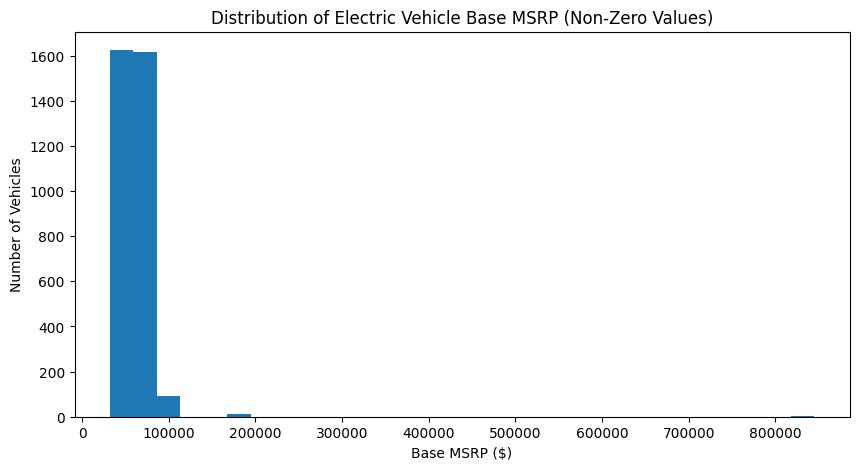

In [ ]:
plt.figure(figsize=(10, 5))

msrp_nonzero.plot(kind="hist", bins=30)

plt.title("Distribution of Electric Vehicle Base MSRP (Non-Zero Values)")
plt.xlabel("Base MSRP ($)")
plt.ylabel("Number of Vehicles")

plt.show()

## EDA 11: Average Electric Range by Model Year

In [ ]:
range_by_year = (
    df_clean.groupby("Model Year")["Electric Range"]
    .mean()
    .sort_index()
)

range_by_year

,Electric Range
Model Year,
1997,39.000000
1998,58.000000
1999,74.000000
2000,58.000000
2002,95.000000
2003,95.000000
2008,220.000000
2010,226.086957
2011,70.891613


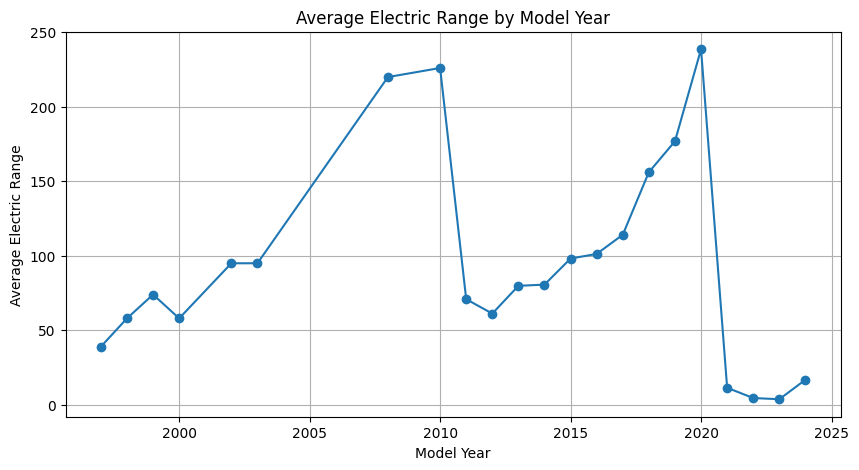

In [ ]:
plt.figure(figsize=(10, 5))

range_by_year.plot(kind="line", marker="o")

plt.title("Average Electric Range by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Average Electric Range")
plt.grid(True)

plt.show()

Finding: The average electric range varies considerably across model years. The highest average range in the dataset is observed around 2020, at approximately 239 miles, followed by 2010 at approximately 226 miles and 2009 at approximately 220 miles. The average range changes substantially across different years, with some earlier years showing relatively high values. A sharp decline is visible after 2020, with very low average ranges in 2021–2023. This decline should be interpreted carefully because the dataset contains many records with an electric range of zero.

## Bivariate Analysis 2: EV Type vs CAFV Eligibility

In [ ]:
ev_cafv = pd.crosstab(
    df_clean["Electric Vehicle Type"],
    df_clean["Clean Alternative Fuel Vehicle (CAFV) Eligibility"]
)

ev_cafv

Clean Alternative Fuel Vehicle (CAFV) Eligibility,Clean Alternative Fuel Vehicle Eligible,Eligibility unknown as battery range has not been researched,Not eligible due to low battery range
Electric Vehicle Type,,,
Battery Electric Vehicle (BEV),47252,91950,8
Plug-in Hybrid Electric Vehicle (PHEV),19079,0,19577


Finding: The bivariate analysis shows a clear difference in CAFV eligibility between BEVs and PHEVs. Among BEVs, 47,252 vehicles are CAFV eligible, while 91,950 have unknown eligibility. Among PHEVs, 19,079 vehicles are CAFV eligible and 19,577 are not eligible due to low battery range. This indicates that CAFV eligibility patterns differ substantially between the two vehicle types.

## Bivariate Analysis 3: EV Type vs Electric Range

In [ ]:
range_by_type = (
    df_clean.groupby("Electric Vehicle Type")["Electric Range"]
    .mean()
    .sort_values(ascending=False)
)

range_by_type

,Electric Range
Electric Vehicle Type,
Battery Electric Vehicle (BEV),66.627318
Plug-in Hybrid Electric Vehicle (PHEV),30.805852


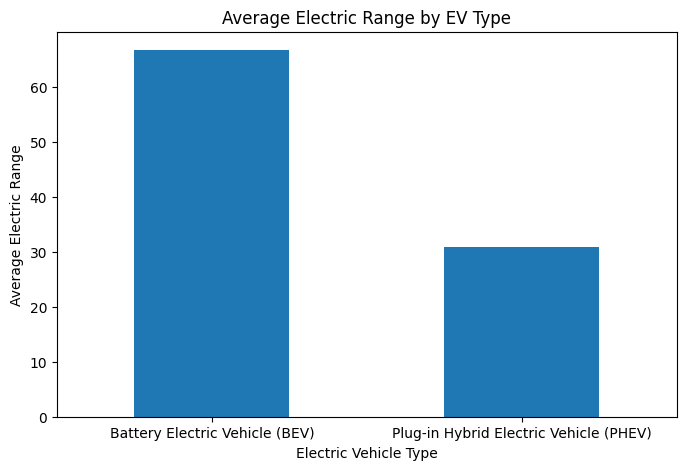

In [ ]:
plt.figure(figsize=(8, 5))

range_by_type.plot(kind="bar")

plt.title("Average Electric Range by EV Type")
plt.xlabel("Electric Vehicle Type")
plt.ylabel("Average Electric Range")
plt.xticks(rotation=0)

plt.show()

Finding: The analysis shows that Battery Electric Vehicles (BEVs) have a higher average electric range of approximately 66.7, compared with approximately 30.9 for Plug-in Hybrid Electric Vehicles (PHEVs). This indicates that BEVs generally provide a greater electric-only range than PHEVs in the analyzed dataset.

In [ ]:
multivariate_data = (
    df_clean
    .groupby(["Model Year", "Electric Vehicle Type"])["Electric Range"]
    .mean()
    .reset_index()
)

multivariate_data.head()

,Model Year,Electric Vehicle Type,Electric Range
0,1997,Battery Electric Vehicle (BEV),39.0
1,1998,Battery Electric Vehicle (BEV),58.0
2,1999,Battery Electric Vehicle (BEV),74.0
3,2000,Battery Electric Vehicle (BEV),58.0
4,2002,Battery Electric Vehicle (BEV),95.0


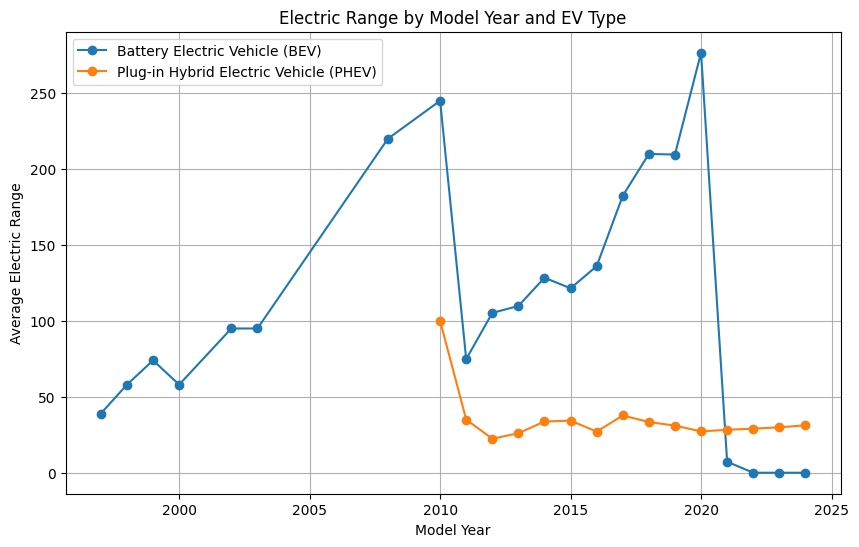

In [ ]:
plt.figure(figsize=(10, 6))

for ev_type in multivariate_data["Electric Vehicle Type"].unique():
    data = multivariate_data[
        multivariate_data["Electric Vehicle Type"] == ev_type
    ]

    plt.plot(
        data["Model Year"],
        data["Electric Range"],
        marker="o",
        label=ev_type
    )

plt.title("Electric Range by Model Year and EV Type")
plt.xlabel("Model Year")
plt.ylabel("Average Electric Range")
plt.legend()
plt.grid(True)

plt.show()

Finding: The analysis shows that Battery Electric Vehicles (BEVs) generally have a higher average electric range than Plug-in Hybrid Electric Vehicles (PHEVs) across the model years. BEV range varies considerably over the years, reaching its highest level around 2020, while PHEV range remains comparatively lower and more stable. The results indicate that both vehicle type and model year influence the observed electric range.

# EDA Summary

The Electric Vehicle dataset was analyzed using Python and Pandas. The data preparation process included checking the dataset structure, missing/null values, duplicate records, data types, categorical values, numerical values, and potential unusual values.

After data preparation, Exploratory Data Analysis (EDA) was performed using Univariate, Bivariate, and Multivariate analysis.

### Univariate Analysis
The analysis covered:
- EV manufacturers
- EV models
- EV types
- Electric range
- CAFV eligibility
- State and city distribution
- Model year
- Base MSRP

### Bivariate Analysis
The relationships analyzed included:
- Model Year vs Electric Range
- EV Type vs CAFV Eligibility
- EV Type vs Electric Range

### Multivariate Analysis
The analysis considered:
- Model Year + EV Type + Electric Range

Various charts such as bar charts, histograms, and line charts were used to identify important patterns and trends in the dataset.

The key findings from this EDA will be used as the basis for developing the Power BI dashboard.

In [ ]:
# Save cleaned dataset for Power BI
df_clean.to_csv("Electric_Vehicle_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
